# Decision Tree: When Does It Overfit?
Owner: Anupama Singh

**Overfitting** means the model learns the training students so closely (including their noise) that it does worse on
new students. The sign is a growing gap: training accuracy keeps rising while accuracy on unseen schools falls.

This notebook grows Decision Trees of increasing depth and compares training and test accuracy, in two settings:

| Setting | `min_samples_leaf` | Meaning |
|---|---|---|
| **No leaf limit** | 1 | a leaf can hold a single student, so the tree can memorize the training data |
| **Leaf limit (our notebook)** | 20 | every leaf must hold at least 20 students, as in `anupama_decision_tree_cv.ipynb` |

Depths tested: 2 to 8, then 10, 12, 15, 20 and unlimited. Same 706 students, 16 features and 5-fold school-grouped
cross-validation as the other baseline notebooks.

## 1. Setup and data

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, roc_auc_score, average_precision_score

LOCAL = Path("../data")
URL = "https://raw.githubusercontent.com/ecri-data/ECRI-Dataset/main/ECRI"
src = LOCAL if (LOCAL / "ECRIDataSet.csv").exists() else URL
# Outputs go to their own folder: results/decision_tree_overfitting/
RESULTS = (Path("../results") if Path("../results").exists() else Path("results")) / "decision_tree_overfitting"
RESULTS.mkdir(parents=True, exist_ok=True)

FEATURES = ["Gender", "Tx", "Age1b", "Tier2_N", "grp_rate", "rcmistot", "gnrl_fid",
            "TKPctCrct", "NWFcls", "NWFwrc", "ORFwc", "SAwrS", "SAsrS", "SAtoS", "RMwidRS", "RMwdaRS"]
TARGETS = {"Word Identification": "RMwidRS", "Word Attack": "RMwdaRS"}

df = pd.read_csv(f"{src}/ECRIDataSet.csv")
data = df[df["RMwidRS_target"].notna()].dropna(subset=FEATURES).reset_index(drop=True)
X, groups = data[FEATURES], data["SchlID"]
print(f"Students: {len(data)} | Schools: {groups.nunique()}")

Students: 706 | Schools: 42


## 2. Grow trees of every depth
For each fold, each tree is trained on 4 folds of schools and tested on the 5th. We record:
- **Train accuracy**: accuracy on the students the tree was trained on
- **Test accuracy** and **test ROC AUC**: on the held-out schools the tree never saw
- **Actual depth** and **number of leaves**: how big the tree really grew

In [2]:
DEPTHS = [2, 3, 4, 5, 6, 7, 8, 10, 12, 15, 20, None]
LEAF_SETTINGS = {"No leaf limit (min 1 per leaf)": 1, "Leaf limit (min 20 per leaf)": 20}

rows = []
for target_name, score in TARGETS.items():
    y = data[f"{score}_target"].astype(int)
    for fold, (tr, te) in enumerate(GroupKFold(n_splits=5).split(X, y, groups), start=1):
        for setting, leaf in LEAF_SETTINGS.items():
            for depth in DEPTHS:
                tree = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=leaf, random_state=0)
                tree.fit(X.iloc[tr], y.iloc[tr])
                proba = tree.predict_proba(X.iloc[te])[:, 1]
                rows.append({"target": target_name, "setting": setting, "fold": fold,
                             "depth": "unlimited" if depth is None else depth,
                             "Train accuracy": accuracy_score(y.iloc[tr], tree.predict(X.iloc[tr])),
                             "Test accuracy": accuracy_score(y.iloc[te], tree.predict(X.iloc[te])),
                             "Test ROC AUC": roc_auc_score(y.iloc[te], proba),
                             "Test PR-AUC": average_precision_score(y.iloc[te], proba),
                             "Actual depth": tree.get_depth(), "Leaves": tree.get_n_leaves()})
results = pd.DataFrame(rows)
summary = (results.groupby(["target", "setting", "depth"], sort=False)
           [["Train accuracy", "Test accuracy", "Test ROC AUC", "Test PR-AUC", "Actual depth", "Leaves"]]
           .mean().round(3))
summary["Gap (train - test)"] = (summary["Train accuracy"] - summary["Test accuracy"]).round(3)
summary.to_csv(RESULTS / "decision_tree_overfitting.csv")

## 3. No leaf limit: the tree overfits as it grows deeper
Read the **Gap** column: the difference between training and test accuracy.

In [3]:
summary.loc[("Word Identification", "No leaf limit (min 1 per leaf)")]

,Train accuracy,Test accuracy,Test ROC AUC,Test PR-AUC,Actual depth,Leaves,Gap (train - test)
depth,,,,,,,
2,0.667,0.646,0.653,0.639,2.0,4.0,0.021
3,0.691,0.646,0.635,0.627,3.0,8.0,0.045
4,0.704,0.637,0.623,0.619,4.0,14.4,0.067
5,0.742,0.610,0.604,0.602,5.0,24.4,0.132
6,0.772,0.586,0.592,0.596,6.0,35.6,0.186
7,0.817,0.586,0.585,0.585,7.0,48.4,0.231
8,0.853,0.598,0.599,0.599,8.0,61.2,0.255
10,0.926,0.572,0.578,0.587,10.0,90.4,0.354
12,0.980,0.565,0.566,0.582,12.0,112.4,0.415


In [4]:
summary.loc[("Word Attack", "No leaf limit (min 1 per leaf)")]

,Train accuracy,Test accuracy,Test ROC AUC,Test PR-AUC,Actual depth,Leaves,Gap (train - test)
depth,,,,,,,
2,0.636,0.558,0.528,0.603,2.0,4.0,0.078
3,0.664,0.589,0.570,0.629,3.0,7.8,0.075
4,0.699,0.584,0.552,0.621,4.0,13.8,0.115
5,0.734,0.569,0.560,0.635,5.0,22.6,0.165
6,0.780,0.554,0.547,0.618,6.0,33.8,0.226
7,0.815,0.547,0.531,0.611,7.0,48.0,0.268
8,0.853,0.518,0.514,0.596,8.0,63.2,0.335
10,0.930,0.528,0.514,0.597,10.0,94.2,0.402
12,0.971,0.540,0.527,0.600,12.0,114.6,0.431


## 4. Leaf limit of 20 (our setting): deeper limits change nothing
With at least 20 students per leaf, the tree runs out of students to split at about depth 8, so depth 10, 12, 15,
20 and unlimited all give the same tree.

In [5]:
summary.loc[("Word Identification", "Leaf limit (min 20 per leaf)")]

,Train accuracy,Test accuracy,Test ROC AUC,Test PR-AUC,Actual depth,Leaves,Gap (train - test)
depth,,,,,,,
2,0.665,0.650,0.662,0.646,2.0,4.0,0.015
3,0.683,0.644,0.656,0.643,3.0,7.6,0.039
4,0.694,0.643,0.647,0.654,4.0,11.8,0.051
5,0.705,0.632,0.639,0.649,5.0,15.2,0.073
6,0.718,0.610,0.632,0.649,6.0,18.8,0.108
7,0.724,0.606,0.633,0.660,7.0,21.0,0.118
8,0.726,0.614,0.635,0.655,7.6,21.6,0.112
10,0.726,0.614,0.638,0.664,7.8,21.8,0.112
12,0.726,0.614,0.638,0.664,7.8,21.8,0.112


In [6]:
summary.loc[("Word Attack", "Leaf limit (min 20 per leaf)")]

,Train accuracy,Test accuracy,Test ROC AUC,Test PR-AUC,Actual depth,Leaves,Gap (train - test)
depth,,,,,,,
2,0.631,0.544,0.519,0.600,2.0,3.8,0.087
3,0.656,0.579,0.561,0.630,3.0,7.0,0.077
4,0.675,0.572,0.577,0.637,4.0,10.8,0.103
5,0.688,0.578,0.573,0.634,5.0,14.6,0.110
6,0.701,0.575,0.583,0.651,6.0,17.6,0.126
7,0.704,0.582,0.573,0.641,6.6,19.0,0.122
8,0.706,0.581,0.573,0.639,7.0,19.8,0.125
10,0.708,0.584,0.578,0.645,7.6,20.6,0.124
12,0.708,0.584,0.578,0.645,7.6,20.6,0.124


## 5. The picture
Solid line = training accuracy, dashed line = accuracy on unseen schools. The widening gap between them is
overfitting.

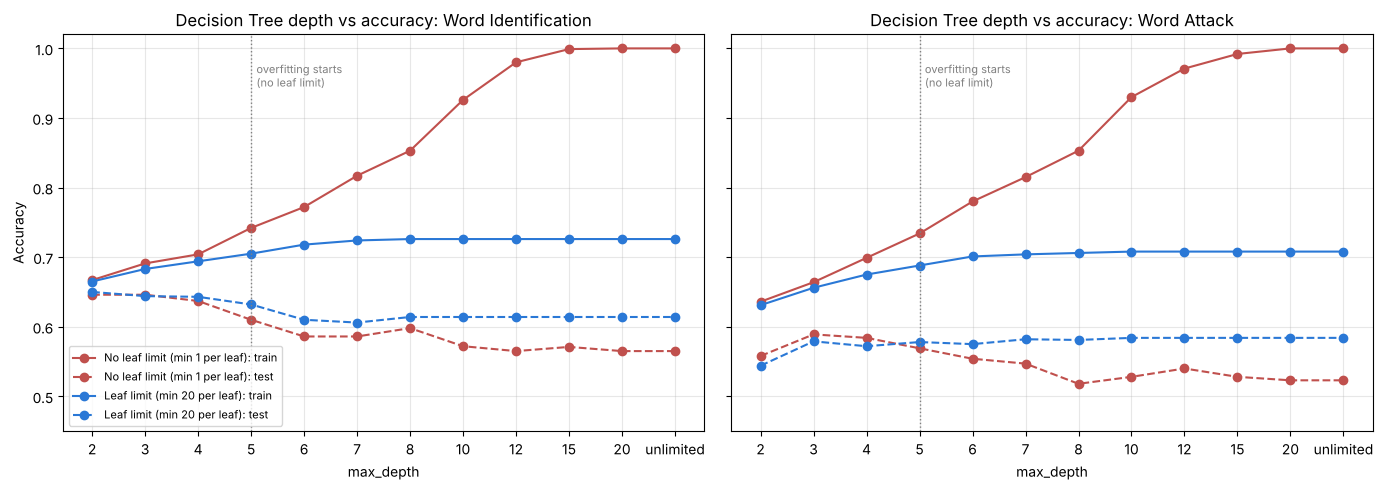

In [7]:
labels = [str(d) for d in summary.loc[("Word Identification", "No leaf limit (min 1 per leaf)")].index]
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
colors = {"No leaf limit (min 1 per leaf)": "#c0504d", "Leaf limit (min 20 per leaf)": "#2a78d6"}
for ax, target_name in zip(axes, TARGETS):
    for setting, color in colors.items():
        t = summary.loc[(target_name, setting)]
        ax.plot(labels, t["Train accuracy"], marker="o", color=color, label=f"{setting}: train")
        ax.plot(labels, t["Test accuracy"], marker="o", linestyle="--", color=color, label=f"{setting}: test")
    ax.axvline(labels.index("5"), color="gray", linestyle=":", linewidth=1)
    ax.text(labels.index("5") + 0.1, 0.98, "overfitting starts\n(no leaf limit)", fontsize=8, va="top", color="gray")
    ax.set_title(f"Decision Tree depth vs accuracy: {target_name}")
    ax.set_xlabel("max_depth")
    ax.set_ylim(0.45, 1.02)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Accuracy")
axes[0].legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.savefig(RESULTS / "decision_tree_overfitting.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Does tuning over deeper trees help?
The Decision Tree notebook tunes the depth from 2 to 8 inside each training fold. Here the same tuning is repeated
with depths up to 20 and unlimited added. The test fold is never used to choose the depth.

In [8]:
def pick_depth(depths, X_train, y_train, groups_train):
    scores = {d: cross_val_score(DecisionTreeClassifier(max_depth=d, min_samples_leaf=20, random_state=0),
                                 X_train, y_train, cv=GroupKFold(4), groups=groups_train, scoring="roc_auc").mean()
              for d in depths}
    return max(scores, key=scores.get)


GRIDS = {"tuned 2-8 (current)": [2, 3, 4, 5, 6, 7, 8], "tuned 2-20 + unlimited": DEPTHS}
rows = []
for target_name, score in TARGETS.items():
    y = data[f"{score}_target"].astype(int)
    for fold, (tr, te) in enumerate(GroupKFold(n_splits=5).split(X, y, groups), start=1):
        for grid_name, grid in GRIDS.items():
            d = pick_depth(grid, X.iloc[tr], y.iloc[tr], groups.iloc[tr])
            tree = DecisionTreeClassifier(max_depth=d, min_samples_leaf=20, random_state=0).fit(X.iloc[tr], y.iloc[tr])
            rows.append({"target": target_name, "grid": grid_name, "fold": fold,
                         "chosen depth": "unlimited" if d is None else d,
                         "Test accuracy": accuracy_score(y.iloc[te], tree.predict(X.iloc[te])),
                         "Test ROC AUC": roc_auc_score(y.iloc[te], tree.predict_proba(X.iloc[te])[:, 1])})
tuned = pd.DataFrame(rows)
display(tuned.pivot_table(index=["target", "fold"], columns="grid", values="chosen depth", aggfunc="first"))
tuned.groupby(["target", "grid"])[["Test accuracy", "Test ROC AUC"]].mean().round(3)

grid                      tuned 2-20 + unlimited  tuned 2-8 (current)
target              fold                                             
Word Attack         1                          5                    5
                    2                          8                    8
                    3                          6                    6
                    4                          3                    3
                    5                          3                    3
Word Identification 1                          3                    3
                    2                          3                    3
                    3                          3                    3
                    4                          8                    8
                    5                          2                    2

Test accuracy  Test ROC AUC
target              grid                                               
Word Attack         tuned 2-20 + unlimited           0.56         0.556
                    tuned 2-8 (current)              0.56         0.556
Word Identification tuned 2-20 + unlimited           0.64         0.653
                    tuned 2-8 (current)              0.64         0.653

## 7. Conclusions
**When does the Decision Tree overfit?**

| Depth (no leaf limit) | Train accuracy | Test accuracy (Word ID) | What happens |
|---|---|---|---|
| 2 to 3 | 0.67 to 0.69 | 0.646 | fits well, small gap |
| 4 | 0.704 | 0.637 | gap starts to grow |
| **5** | **0.742** | **0.610** | **overfitting starts** |
| 8 | 0.853 | 0.598 | large gap |
| 20 / unlimited | 1.000 | 0.565 | memorizes the training students |

- **Without a leaf limit, the tree starts overfitting at depth 5.** At depth 20 it is 100% accurate on the training
  students but only 56.5% on new schools; for Word Attack it falls to guessing (ROC AUC 0.505).
- **Depth 20 with no leaf limit overfits. A minimum of 20 students per leaf prevents it:** the tree stops growing at
  about depth 8 whatever limit is set, training accuracy stays around 0.73, and test accuracy stays around 0.61 to
  0.64.
- **Tuning over deeper trees changes nothing:** the inner cross-validation picks exactly the same depths as with
  2 to 8, so the results are identical.
- **Shallow trees (depth 2 to 4) generalize best.** This matches the rest of our findings: the data carries a weak
  signal, so a simple model is enough and a complex one only memorizes noise.